# 05 — Part F hyperparameter optimisation



## 1. Reuse the Model Training development split



In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.model_selection import ParameterGrid, StratifiedKFold

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
cleaned = root / 'data' / 'processed' / 'loan_default_cleaned.csv'
if not cleaned.is_file():
    raise FileNotFoundError('Open Notebook 05 from the project root or notebooks folder.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.data_preparation import split_loan_data
from src.model_tuning import MODEL_NAMES, SEARCH_GRIDS, SEED, make_pipeline, tune_model

tables = root / 'outputs' / 'tables' / 'part_f'
figures = root / 'outputs' / 'figures' / 'part_f'
tables.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

X_dev, X_holdout, y_dev, _ = split_loan_data(pd.read_csv(cleaned))
assert X_dev.index.intersection(X_holdout.index).empty
print(f'{len(X_dev):,} development rows ({y_dev.mean():.2%} defaults) | {len(X_holdout):,} reserved rows')
outer_folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_dev, y_dev))
validation_positions = np.concatenate([validation for _, validation in outer_folds])
np.testing.assert_array_equal(np.sort(validation_positions), np.arange(len(X_dev)))
print(f'Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | XGBoost {xgboost.__version__}')

118,936 development rows (24.64% defaults) | 29,734 reserved rows
Python 3.12.14 | scikit-learn 1.9.0 | XGBoost 3.4.1


## 2. Document the search space



In [2]:
grid_rows = [
    {'model': name, 'parameters': json.dumps(settings, sort_keys=True)}
    for name, grid in SEARCH_GRIDS.items()
    for settings in ParameterGrid(grid)
]
display(pd.DataFrame(grid_rows))

,model,parameters
0,Logistic Regression,"{""model__C"": 1.0, ""prepare__log_income"": false}"
1,Logistic Regression,"{""model__C"": 1.0, ""prepare__log_income"": true}"
2,Logistic Regression,"{""model__C"": 0.01, ""prepare__log_income"": false}"
3,Logistic Regression,"{""model__C"": 0.01, ""prepare__log_income"": true}"
4,Logistic Regression,"{""model__C"": 0.1, ""prepare__log_income"": false}"
5,Logistic Regression,"{""model__C"": 0.1, ""prepare__log_income"": true}"
6,Logistic Regression,"{""model__C"": 10.0, ""prepare__log_income"": false}"
7,Logistic Regression,"{""model__C"": 10.0, ""prepare__log_income"": true}"
8,Random Forest,"{""model__max_depth"": 12, ""model__min_samples_l..."
9,Random Forest,"{""model__max_depth"": 12, ""model__min_samples_l..."


## 3. Run nested validation and select final settings



In [3]:
fold_parts, candidate_parts, selected = [], [], {}
for name in MODEL_NAMES:
    model_folds, model_candidates, selected[name] = tune_model(name, X_dev, y_dev, outer_folds)
    fold_parts.append(model_folds)
    candidate_parts.append(model_candidates)

fold_scores = pd.concat(fold_parts, ignore_index=True)
candidates = pd.concat(candidate_parts, ignore_index=True)
assert not fold_scores.duplicated(['model', 'fold', 'variant']).any()
assert len(candidates) == 4 * len(grid_rows)
assert candidates.groupby(['model', 'scope'])['selected'].sum().eq(1).all()
assert np.isfinite(fold_scores[['ap', 'roc_auc', 'top10_precision', 'top10_recall']]).all().all()
fold_scores.to_csv(tables / 'outer_fold_scores.csv', index=False)
candidates.to_csv(tables / 'search_candidates.csv', index=False)

Logistic Regression | outer fold 1 complete


Logistic Regression | outer fold 2 complete


Logistic Regression | outer fold 3 complete


Random Forest | outer fold 1 complete


Random Forest | outer fold 2 complete


Random Forest | outer fold 3 complete


XGBoost | outer fold 1 complete


XGBoost | outer fold 2 complete


XGBoost | outer fold 3 complete


## 4. Measure the change against Part E



The matched baselines reproduce the saved Part E fold scores.


,model,raw_ap,matched_reference,reference_ap,nested_ap,nested_ap_sd,ap_change_vs_reference_pp,folds_improved,reference_roc_auc,nested_roc_auc,reference_top10_precision,nested_top10_precision,reference_top10_recall,nested_top10_recall
2,XGBoost,0.5749,Part E raw,0.5749,0.5794,0.0053,0.4503,3,0.7484,0.7517,0.7100,0.7154,0.2881,0.2903
1,Random Forest,0.5565,Part E raw,0.5565,0.5665,0.0055,1.0039,3,0.7381,0.7460,0.6881,0.6976,0.2792,0.2831
0,Logistic Regression,0.4731,Part E log,0.5193,0.5192,0.0064,-0.0025,1,0.7156,0.7155,0.6425,0.6422,0.2607,0.2606


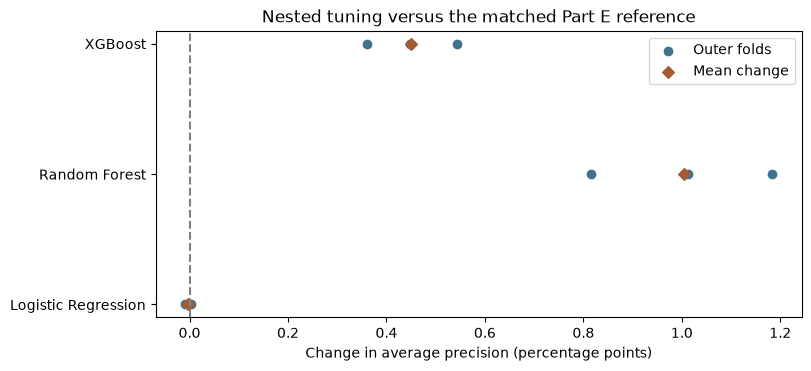

In [4]:
reference_labels = {'Logistic Regression': 'Part E log', 'Random Forest': 'Part E raw', 'XGBoost': 'Part E raw'}
part_e_path = root / 'outputs' / 'tables' / 'part_e' / 'fold_metrics.csv'
if part_e_path.is_file():
    saved = pd.read_csv(part_e_path).set_index(['model', 'fold', 'variant'])['ap']
    for row in fold_scores[fold_scores['variant'].str.startswith('Part E')].itertuples():
        variant = 'Log' if row.variant == 'Part E log' else 'Raw'
        np.testing.assert_allclose(row.ap, saved.loc[row.model, row.fold, variant], atol=1e-5)
    print('The matched baselines reproduce the saved Part E fold scores.')

comparison = []
paired_deltas = {}
for name, control_label in reference_labels.items():
    model_folds = fold_scores.query('model == @name')
    raw = model_folds.query("variant == 'Part E raw'").set_index('fold')
    control = model_folds.query('variant == @control_label').set_index('fold')
    tuned = model_folds.query("variant == 'Nested tuned'").set_index('fold')
    delta = 100 * (tuned['ap'] - control['ap'])
    paired_deltas[name] = delta
    comparison.append({
        'model': name,
        'raw_ap': raw['ap'].mean(),
        'matched_reference': control_label,
        'reference_ap': control['ap'].mean(),
        'nested_ap': tuned['ap'].mean(),
        'nested_ap_sd': tuned['ap'].std(),
        'ap_change_vs_reference_pp': delta.mean(),
        'folds_improved': int((delta > 1e-10).sum()),
        'reference_roc_auc': control['roc_auc'].mean(),
        'nested_roc_auc': tuned['roc_auc'].mean(),
        'reference_top10_precision': control['top10_precision'].mean(),
        'nested_top10_precision': tuned['top10_precision'].mean(),
        'reference_top10_recall': control['top10_recall'].mean(),
        'nested_top10_recall': tuned['top10_recall'].mean(),
    })

summary = pd.DataFrame(comparison).sort_values('nested_ap', ascending=False)
summary.to_csv(tables / 'baseline_vs_tuned.csv', index=False)
display(summary.round(4))

fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
for i, name in enumerate(summary['model']):
    deltas = paired_deltas[name]
    ax.scatter(deltas, np.full(len(deltas), i), color='#40728E', label='Outer folds' if i == 0 else None)
    ax.scatter(deltas.mean(), i, marker='D', color='#A55C35', label='Mean change' if i == 0 else None)
ax.axvline(0, linestyle='--', color='grey')
ax.set(yticks=np.arange(len(summary)), yticklabels=summary['model'],
       xlabel='Change in average precision (percentage points)',
       title='Nested tuning versus the matched Part E reference')
ax.invert_yaxis()
ax.legend()
fig.savefig(figures / 'tuning_ap_change.png', dpi=160)
plt.show()

## 5. Save the settings for Part G


In [5]:
settings_path = tables / 'selected_parameters.json'
settings_path.write_text(json.dumps(selected, indent=2, sort_keys=True) + '\n', encoding='utf-8')
restored = json.loads(settings_path.read_text(encoding='utf-8'))
for name, params in restored.items():
    pipeline = make_pipeline(name, params)
    assert all(pipeline.get_params()[key] == value for key, value in params.items())

final_winners = candidates.query("scope == 'final_development_search' and selected")
display(final_winners[['model', 'parameters', 'mean_ap', 'sd_ap']].reset_index(drop=True))
for row in summary.itertuples():
    nested_choices = fold_scores.query("model == @row.model and variant == 'Nested tuned'")['parameters'].nunique()
    print(f'{row.model}: {row.ap_change_vs_reference_pp:+.3f} AP percentage points vs {row.matched_reference}. '
          f'Improved in {row.folds_improved}/3 folds, with {nested_choices} distinct inner-search choices.')

,model,parameters,mean_ap,sd_ap
0,Logistic Regression,"{""model__C"": 1.0, ""prepare__log_income"": true}",0.519251,0.005261
1,Random Forest,"{""model__max_depth"": 18, ""model__min_samples_l...",0.566515,0.004476
2,XGBoost,"{""model__learning_rate"": 0.05, ""model__max_dep...",0.582481,0.004918


XGBoost: +0.450 AP percentage points vs Part E raw. Improved in 3/3 folds, with 1 distinct inner-search choices.
Random Forest: +1.004 AP percentage points vs Part E raw. Improved in 3/3 folds, with 1 distinct inner-search choices.
Logistic Regression: -0.003 AP percentage points vs Part E log. Improved in 1/3 folds, with 1 distinct inner-search choices.
